# Biomedical Image Segmentation with U-Net

Lien de Dataset :
    https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset

In [1]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from glob import glob
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model

In [2]:
import kagglehub

path = kagglehub.dataset_download("aryashah2k/breast-ultrasound-images-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-ultrasound-images-dataset' dataset.
Path to dataset files: /kaggle/input/breast-ultrasound-images-dataset


In [3]:
folder_paths = [path + "/Dataset_BUSI_with_GT/malignant", path + "/Dataset_BUSI_with_GT/benign"] # Paths to the 2 folders

size = 128 # Input size: 128x128

images = [] # Empty list to store the original images in
masks = [] # Empty list to store the masks in

found_mask = False # This flag helps us handle multiple masks for the same image
# Loop through both folders
for folder_path in folder_paths:
    # Loop through all files in the current folder (sorted for consistency)
    for file_path in sorted(glob(folder_path + "/*")):
        # Load and resize the image
        img = cv2.imread(file_path)
        img = cv2.resize(img, (size, size)) # Resize image to 128×128
        img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) # Convert RGB to grayscale
        img = img / 255.0 # Normalize to [0,1]

        if "mask" in file_path: # Checks if the filename contains "mask"
            if found_mask:
                # Combine with the previous mask
                masks[-1] += img
                # Ensure binary output (0 or 1)
                masks[-1] = np.where(masks[-1] > 0.5, 1.0, 0.0)
            else:
                masks.append(img) # Adds the first mask to the list
                found_mask = True
        else:
            images.append(img) # Adds original image to the list
            found_mask = False

# Convert lists to NumPy arrays
X = np.array(images) # Create an array of all original images
y = np.array(masks) # Create an array of all masked imaged (Ground truth)

X = np.expand_dims(X, -1)
y = np.expand_dims(y, -1)

print(f"X shape: {X.shape} | y shape: {y.shape}")
# Split images into training and validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1)

X shape: (647, 128, 128, 1) | y shape: (647, 128, 128, 1)


### Ajouter du code pour visualiser les cartes des caractéristiques (feature maps) de chaque couche dans le modèle U-Net

In [4]:
# Fonction utilitaire : affiche les n premières cartes de caractéristiques (feature maps) d'une couche
def afficher_feature_maps(feature_model, image, titre, n_maps=16):
    # feature_model : sous-modèle (entrée du U-Net -> sortie de la couche choisie)
    # image         : une image de forme (128, 128, 1)
    fmaps = feature_model.predict(np.expand_dims(image, axis=0), verbose=0)[0]  # forme (H, W, nb_canaux)
    n_maps = min(n_maps, fmaps.shape[-1])      # on ne dépasse pas le nombre de canaux disponibles
    cols = 8
    rows = int(np.ceil(n_maps / cols))
    plt.figure(figsize=(cols * 1.6, rows * 1.8 + 0.6))
    plt.suptitle(f"{titre} | forme : {fmaps.shape} | {n_maps} cartes affichées sur {fmaps.shape[-1]}")
    for k in range(n_maps):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(fmaps[:, :, k], cmap="viridis")
        plt.title(f"c{k}", fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


In [5]:
# Build the U-Net
input_layer = Input(shape=(size, size, 1))
conv1 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(input_layer)
conv1 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv1)
pool1 = MaxPooling2D((2, 2))(conv1)

#votre code pour visualiser les cartes des caractéristique de la couche 1 de l'encodeur
feature_models = {}  # dictionnaire : nom de la couche -> sous-modèle qui renvoie ses feature maps
feature_models["Encodeur 1 (conv1)"] = Model(inputs=input_layer, outputs=conv1)

# Second encoder block
conv2 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool1)
conv2 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv2)
pool2 = MaxPooling2D((2, 2))(conv2)

#votre code pour visualiser les cartes des caractéristique de la couche 2 de l'encodeur
feature_models["Encodeur 2 (conv2)"] = Model(inputs=input_layer, outputs=conv2)

# Third encoder block
conv3 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool2)
conv3 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv3)
pool3 = MaxPooling2D((2, 2))(conv3)

#votre code pour visualiser les cartes des caractéristique de la couche 3 de l'encodeur
feature_models["Encodeur 3 (conv3)"] = Model(inputs=input_layer, outputs=conv3)

# Fourth encoder block
conv4 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool3)
conv4 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv4)
pool4 = MaxPooling2D((2, 2))(conv4)

#votre code pour visualiser les cartes des caractéristique de la couche 4 de l'encodeur
feature_models["Encodeur 4 (conv4)"] = Model(inputs=input_layer, outputs=conv4)
# --- Bottleneck ---
bottleneck = Conv2D(1024, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(pool4)
bottleneck = Conv2D(1024, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(bottleneck)

#votre code pour visualiser les cartes des caractéristique de la couche espace latente
feature_models["Espace latent (bottleneck)"] = Model(inputs=input_layer, outputs=bottleneck)
# First decoder block
upconv1 = Conv2DTranspose(512, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(bottleneck)
concat1 = concatenate([upconv1, conv4])
conv5 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat1)
conv5 = Conv2D(512, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv5)

#votre code pour visualiser les cartes des caractéristique de la couche 1 du decodeur
feature_models["Décodeur 1 (conv5)"] = Model(inputs=input_layer, outputs=conv5)

# Second decoder block
upconv2 = Conv2DTranspose(256, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(conv5)
concat2 = concatenate([upconv2, conv3])
conv6 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat2)
conv6 = Conv2D(256, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv6)

#votre code pour visualiser les cartes des caractéristique de la couche 2 du decodeur
feature_models["Décodeur 2 (conv6)"] = Model(inputs=input_layer, outputs=conv6)

# Third decoder block
upconv3 = Conv2DTranspose(128, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(conv6)
concat3 = concatenate([upconv3, conv2])
conv7 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat3)
conv7 = Conv2D(128, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv7)

#votre code pour visualiser les cartes des caractéristique de la couche 3 du decodeur
feature_models["Décodeur 3 (conv7)"] = Model(inputs=input_layer, outputs=conv7)
# Fourth decoder block
upconv4 = Conv2DTranspose(64, (2, 2), strides=2, padding="same",kernel_initializer="he_normal")(conv7)
concat4 = concatenate([upconv4, conv1])
conv8 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(concat4)
conv8 = Conv2D(64, (3, 3), activation="relu", padding="same",kernel_initializer="he_normal")(conv8)

#votre code pour visualiser les cartes des caractéristique de la couche 4 du decodeur
feature_models["Décodeur 4 (conv8)"] = Model(inputs=input_layer, outputs=conv8)
# --- Output layer ---
output_layer = Conv2D(1, (1, 1), activation="sigmoid", padding="same")(conv8)

# --- Model creation ---
model = Model(inputs=input_layer, outputs=output_layer)
model.summary()


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,030,593 (118.37 MB)

 Trainable params: 31,030,593 (118.37 MB)

 Non-trainable params: 0 (0.00 B)

![unet.png](attachment:unet.png)

In [6]:
# Compile and train the model
model.compile(loss="binary_crossentropy", optimizer="Adam", metrics=["accuracy"])
model.fit(X_train, y_train, epochs = 40, validation_data = (X_val,y_val),verbose=1)


Epoch 1/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 139s 4s/step - accuracy: 0.8262 - loss: 0.6833 - val_accuracy: 0.8993 - val_loss: 0.3784
Epoch 2/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 357ms/step - accuracy: 0.9049 - loss: 0.3349 - val_accuracy: 0.8993 - val_loss: 0.2862
Epoch 3/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 363ms/step - accuracy: 0.9049 - loss: 0.3174 - val_accuracy: 0.8993 - val_loss: 0.3220
Epoch 4/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 367ms/step - accuracy: 0.9048 - loss: 0.2981 - val_accuracy: 0.8993 - val_loss: 0.2564
Epoch 5/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 372ms/step - accuracy: 0.9111 - loss: 0.2290 - val_accuracy: 0.9133 - val_loss: 0.2279
Epoch 6/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 374ms/step - accuracy: 0.9193 - loss: 0.2087 - val_accuracy: 0.9158 - val_loss: 0.2108
Epoch 7/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 372ms/step - accuracy: 0.9221 - loss: 0.2012 - val_accuracy: 0.8931 - val_loss: 0.2484
Epoch 8/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 365ms/step - accuracy: 0.9167 - loss: 0.2112 - val_accuracy: 0.9

In [7]:
# Compute IoU
from sklearn.metrics import jaccard_score
# Compute predicted mask
pred=model.predict(X_val,verbose=1)
pred = (pred > 0.5).astype(int) # binarize
y_true = y_val.astype(int)
# Compute IoU based on flatten predictions and ground truths
iou = jaccard_score(pred.flatten(), y_true.flatten())
print(f" IoU (Jaccard Score): {iou:.4f}")


3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 478ms/step
 IoU (Jaccard Score): 0.6327


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


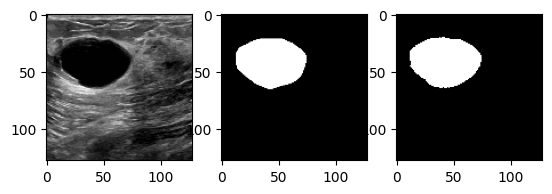

In [8]:
# Plot
i=6 # Try other values
plt.subplot(1, 3, 1)
plt.imshow(X_val[i],cmap="gray")
plt.subplot(1, 3, 2)
plt.imshow(y_val[i],cmap="gray")
plt.subplot(1, 3, 3)
pred=model.predict(np.expand_dims(X_val[i], axis=0),verbose=1)[0]
pred = (pred > 0.5) # binarize
plt.imshow(pred,cmap="gray")

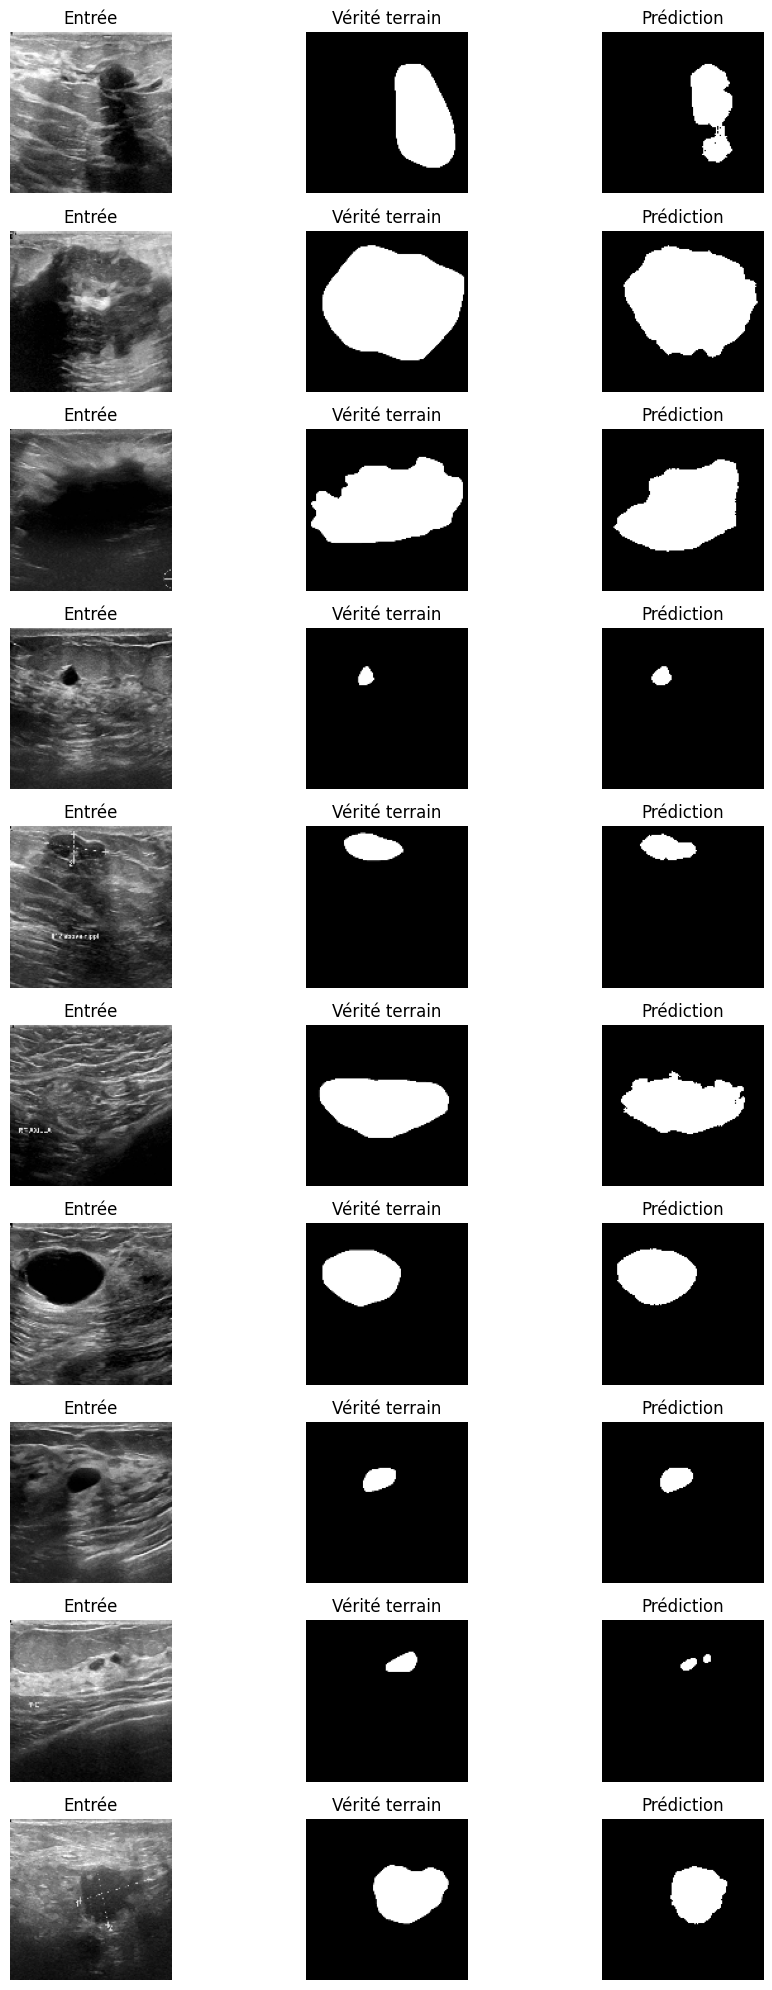

In [9]:
n = 10
plt.figure(figsize=(10, n * 2))

for i in range(n):
    # Image d'entrée
    plt.subplot(n, 3, 3*i + 1)
    plt.imshow(X_val[i], cmap='gray')
    plt.title("Entrée")
    plt.axis('off')

    # Masque réel
    plt.subplot(n, 3, 3*i + 2)
    plt.imshow(y_val[i], cmap='gray')
    plt.title("Vérité terrain")
    plt.axis('off')

    # Prédiction
    pred = model.predict(np.expand_dims(X_val[i], axis=0), verbose=0)[0]
    pred = (pred > 0.5)

    plt.subplot(n, 3, 3*i + 3)
    plt.imshow(pred, cmap='gray')
    plt.title("Prédiction")
    plt.axis('off')

plt.tight_layout()
plt.show()

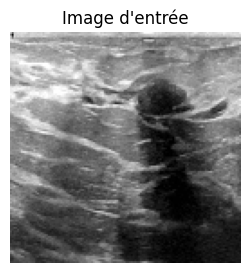

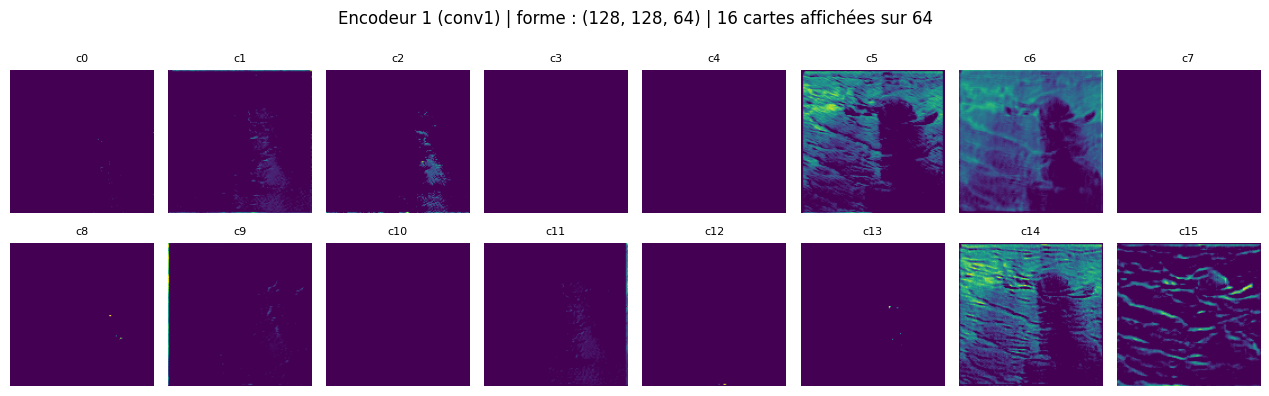

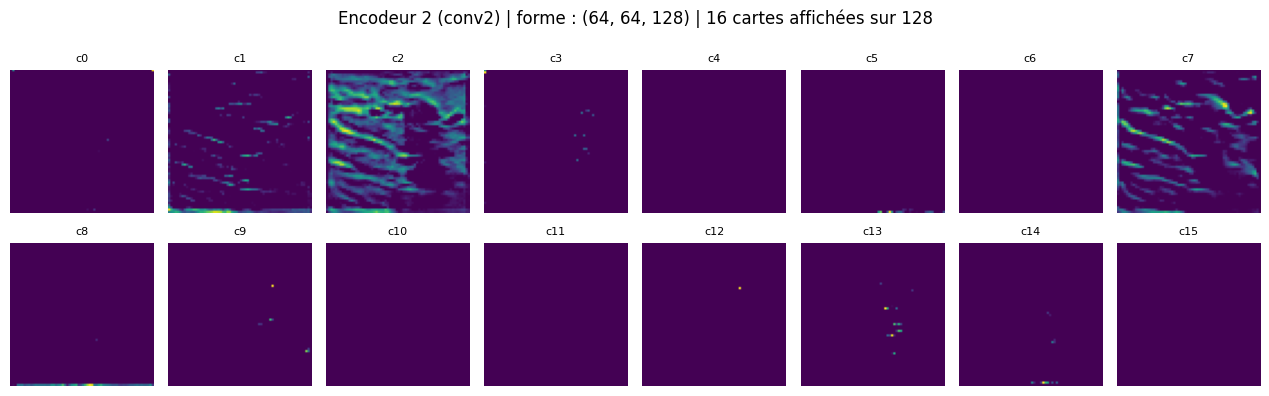

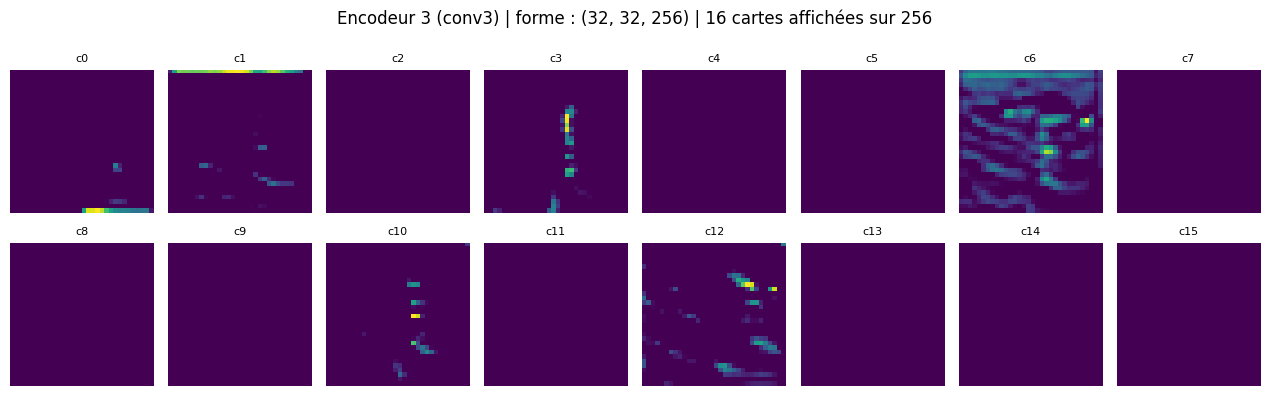

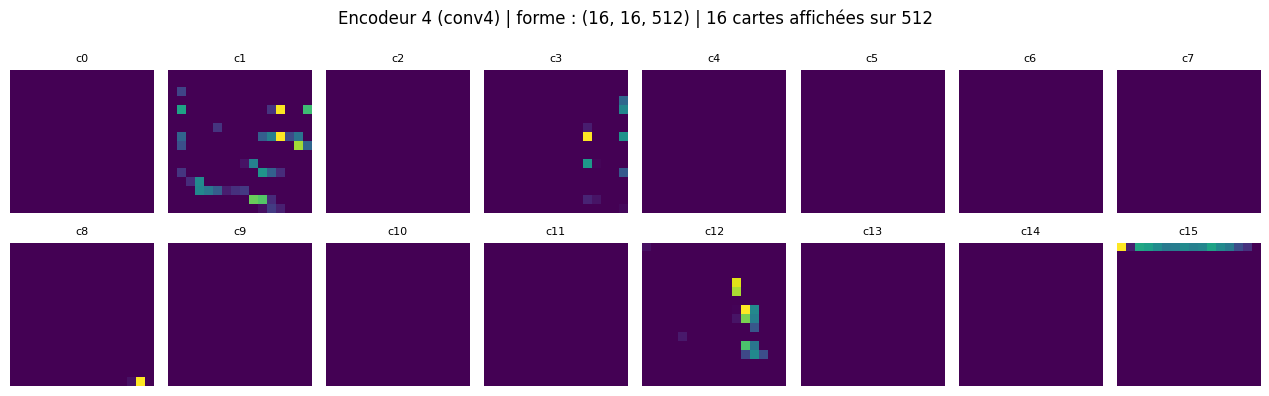

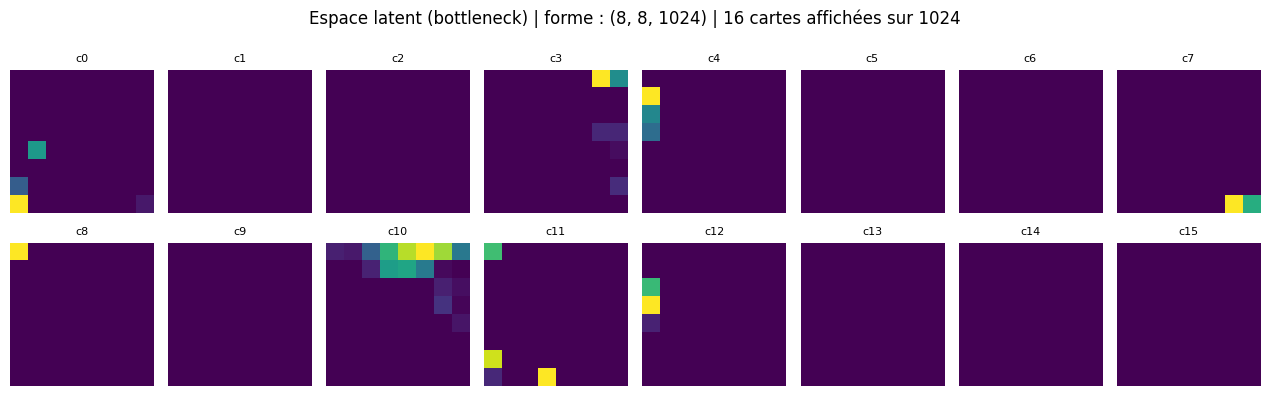

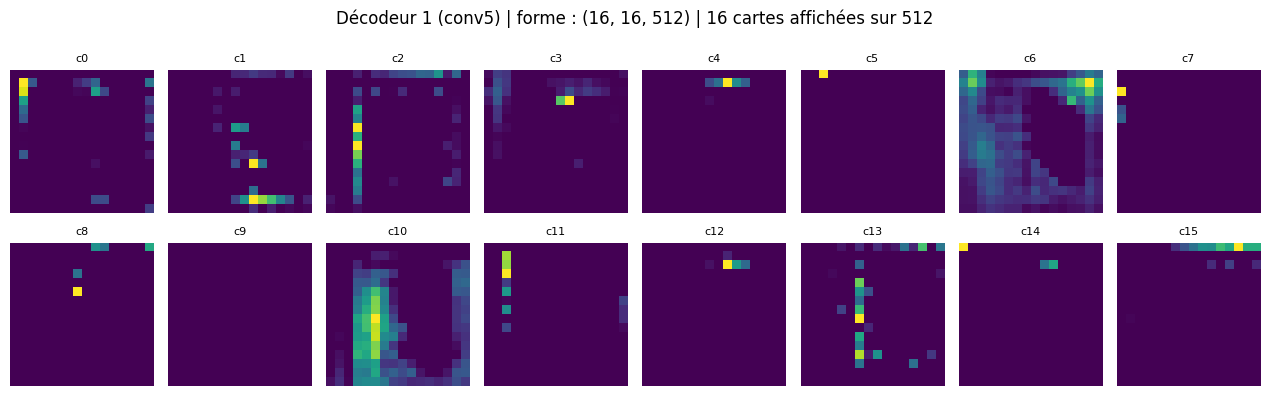

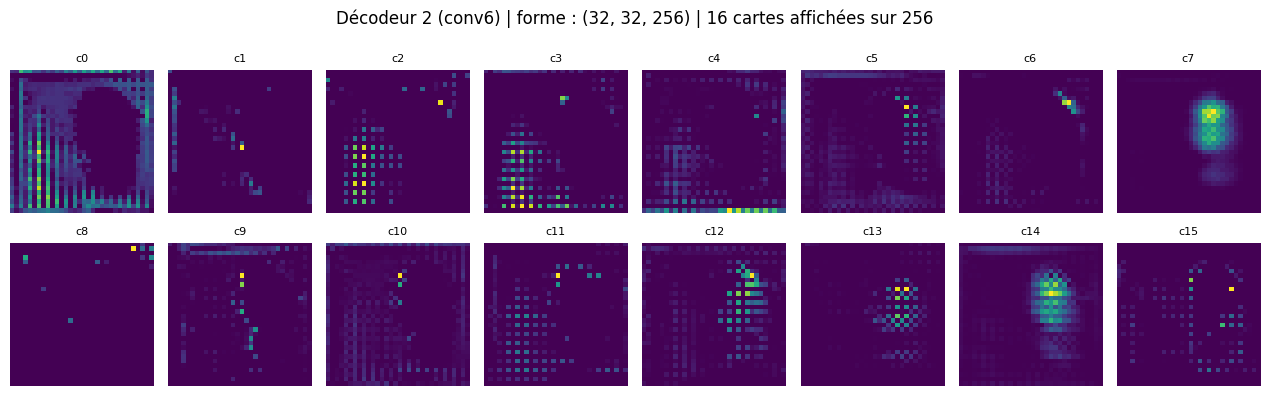

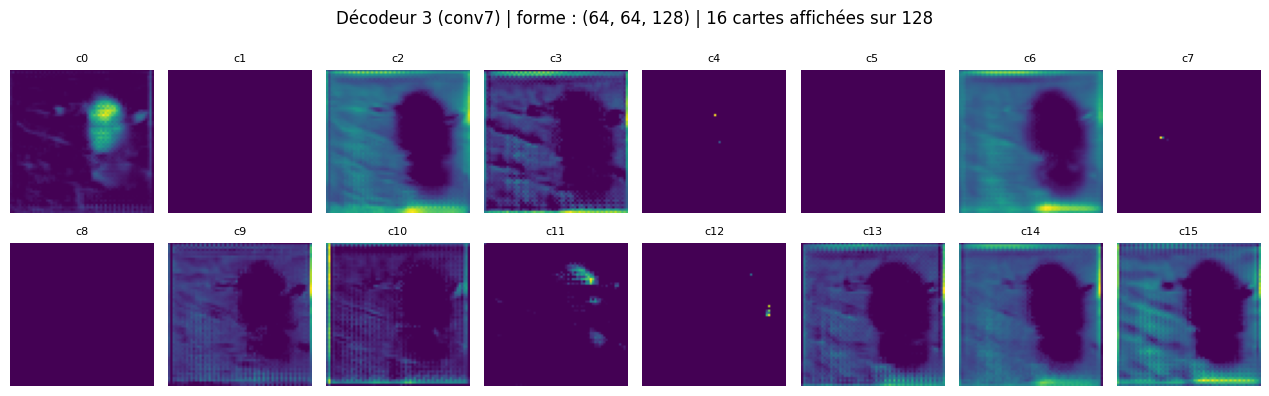

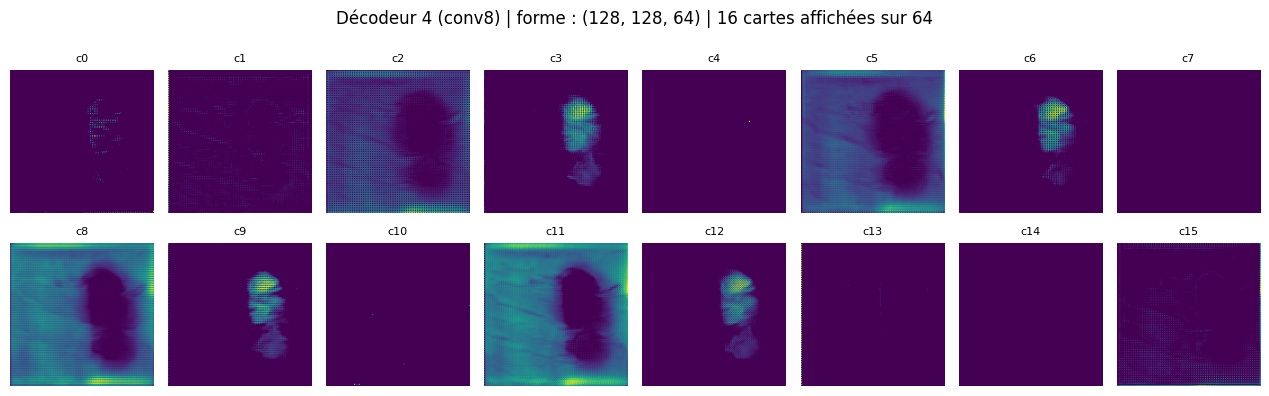

In [10]:
# Visualisation des feature maps de toutes les couches (à exécuter APRÈS l'entraînement)
image_test = X_val[0]   # on peut changer l'indice pour tester une autre image

plt.figure(figsize=(3, 3))
plt.imshow(image_test, cmap="gray")
plt.title("Image d'entrée")
plt.axis("off")
plt.show()

for nom_couche, feature_model in feature_models.items():
    afficher_feature_maps(feature_model, image_test, nom_couche)
